# B02 - Booking Segment Clustering (K-means)

Hotel Booking Cancellation Prediction - Group 5, Part B

## Objective
Use K-means to find distinct booking segments from numerical booking
features, then compare cancellation behaviour across segments
*after* clustering (the label is never used as a clustering input, per the
team agreement and proposal Section 4.4).

## Method summary (agreed with the team before coding)
- Features: `lead_time`, `total_nights`, `total_guests`, `adr`,
  `previous_cancellations` (Section 4.4's proposed set). `adr` is excluded
  from A's primary classification template because its availability at the
  moment a booking is first made has not been confirmed with A - it is used
  here only for descriptive clustering, not as a stand-in for a validated,
  booking-time-available feature. If a cluster defined partly by `adr` is
  later used to inform an initial-booking decision, or to pick a feature or
  threshold for the classification models, that availability question needs
  to be resolved with A first; noting that "clustering is allowed to use it"
  does not settle it.
- Outlier treatment (business-logic, documented, thresholds derived from the
  **training set only**): `adr` and `total_guests` capped at the training
  set's 99th percentile (a handful of extreme/likely-erroneous values);
  `lead_time` and `total_nights` capped at the 99.5th percentile (real but
  rare long-tail values); `previous_cancellations` log1p-transformed
  (zero-inflated count variable - percentile capping at 99/99.5% would
  collapse nearly all of its variance since >99.5% of values are 0 or 1).
- Standardization: `StandardScaler` fit on the training set only.
- Number of clusters: chosen using the elbow method + silhouette score
  (computed on the training set), balanced against business
  interpretability, per Section 4.4.
- Final cluster assignment: the scaler and K-means model are fit on the
  training set, then applied to the full cleaned dataset (118,564 rows) to
  produce the group profiles and cancellation-rate comparison used in the
  report.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
RANDOM_STATE = 42

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
fig_dir = project_root / "results" / "figures"
tab_dir = project_root / "results" / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
tab_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(project_root / "data" / "hotel_bookings_clean.csv")
train_ids = pd.read_csv(project_root / "data" / "splits" / "train_ids.csv")["row_id"]
test_ids = pd.read_csv(project_root / "data" / "splits" / "test_ids.csv")["row_id"]
train_df = df[df["row_id"].isin(train_ids)].copy()

print("Full dataset:", df.shape)
print("Training subset (used to fit scaler / choose k):", train_df.shape)

Full dataset: (118564, 32)
Training subset (used to fit scaler / choose k): (94851, 32)


## 1. Feature engineering for clustering: outlier capping + log transform

Capping thresholds are computed on the **training set only**, then the same
fixed threshold values are applied to the full dataset later, mirroring the
"fit on train, apply to all" convention used throughout the project.

In [2]:
cap_rules = {"adr": 0.99, "total_guests": 0.99, "lead_time": 0.995, "total_nights": 0.995}
cap_values = {feat: train_df[feat].quantile(q) for feat, q in cap_rules.items()}
print("Capping thresholds derived from the training set:")
for feat, val in cap_values.items():
    print(f"  {feat}: capped at {val} (training {cap_rules[feat]*100:.1f}th percentile)")

def engineer_cluster_features(data, cap_values):
    """Apply the agreed outlier treatment. Thresholds must come from the
    training set (passed in via cap_values); this function itself does not
    compute new thresholds, so it is safe to reuse on any subset."""
    out = pd.DataFrame(index=data.index)
    out["lead_time"] = data["lead_time"].clip(upper=cap_values["lead_time"])
    out["total_nights"] = data["total_nights"].clip(upper=cap_values["total_nights"])
    out["total_guests"] = data["total_guests"].clip(upper=cap_values["total_guests"])
    out["adr"] = data["adr"].clip(upper=cap_values["adr"])
    out["previous_cancellations_log"] = np.log1p(data["previous_cancellations"])
    return out

train_feat = engineer_cluster_features(train_df, cap_values)
full_feat = engineer_cluster_features(df, cap_values)

print("\nShare of training rows affected by each cap:")
for feat in ["lead_time", "total_nights", "total_guests", "adr"]:
    affected = (train_df[feat] > cap_values[feat]).mean() * 100
    print(f"  {feat}: {affected:.2f}% of rows capped")

print("\nTraining feature summary after treatment:")
print(train_feat.describe().round(2))

Capping thresholds derived from the training set:
  adr: capped at 252.0 (training 99.0th percentile)
  total_guests: capped at 4.0 (training 99.0th percentile)
  lead_time: capped at 476.0 (training 99.5th percentile)
  total_nights: capped at 14.0 (training 99.5th percentile)

Share of training rows affected by each cap:
  lead_time: 0.49% of rows capped
  total_nights: 0.37% of rows capped
  total_guests: 0.13% of rows capped
  adr: 0.99% of rows capped

Training feature summary after treatment:
       lead_time  total_nights  ...       adr  previous_cancellations_log
count   94851.00      94851.00  ...  94851.00                    94851.00
mean      104.04          3.42  ...    102.12                        0.04
std       105.27          2.33  ...     46.24                        0.20
min         0.00          1.00  ...      0.00                        0.00
25%        18.00          2.00  ...     70.00                        0.00
50%        70.00          3.00  ...     95.00       

## 2. Standardization (fit on training set only)

In [3]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train_feat)
X_full_scaled = scaler.transform(full_feat)
print("X_train_scaled:", X_train_scaled.shape)
print("X_full_scaled:", X_full_scaled.shape)

X_train_scaled: (94851, 5)
X_full_scaled: (118564, 5)


## 3. Choosing k: elbow method + silhouette score (training set)

k=2: inertia(WSS)=  389350.7  silhouette=0.2597
k=3: inertia(WSS)=  312572.3  silhouette=0.3165
k=4: inertia(WSS)=  251128.3  silhouette=0.2904
k=5: inertia(WSS)=  213878.1  silhouette=0.3032
k=6: inertia(WSS)=  187021.9  silhouette=0.3049
k=7: inertia(WSS)=  167515.2  silhouette=0.2955
k=8: inertia(WSS)=  149335.6  silhouette=0.2980
k=9: inertia(WSS)=  139158.5  silhouette=0.2946
k=10: inertia(WSS)=  130896.4  silhouette=0.2742


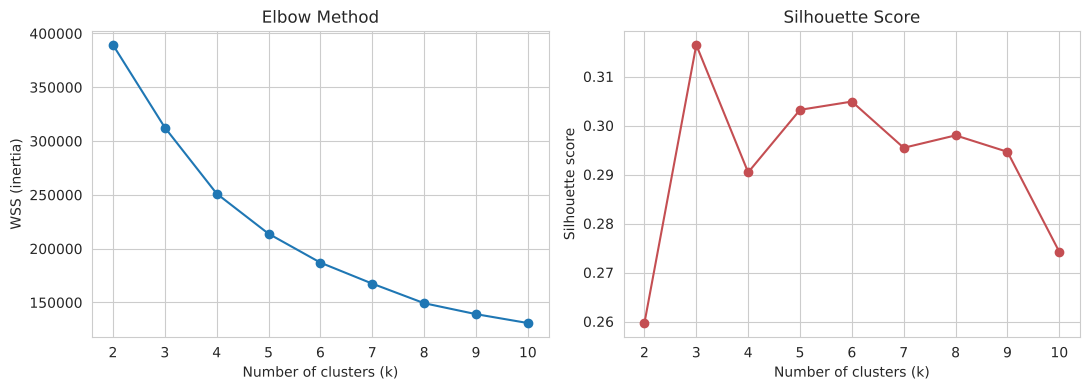

In [4]:
k_range = range(2, 11)
wss, sil = [], []
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_train_scaled), size=12000, replace=False)  # subsample for silhouette speed

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_train_scaled)
    s = silhouette_score(X_train_scaled[sample_idx], labels[sample_idx])
    wss.append(km.inertia_)
    sil.append(s)
    print(f"k={k}: inertia(WSS)={km.inertia_:10.1f}  silhouette={s:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(k_range), wss, marker="o")
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("WSS (inertia)"); axes[0].set_title("Elbow Method")
axes[1].plot(list(k_range), sil, marker="o", color="#C44E52")
axes[1].set_xlabel("Number of clusters (k)"); axes[1].set_ylabel("Silhouette score"); axes[1].set_title("Silhouette Score")
plt.tight_layout()
plt.savefig(fig_dir / "06_k_selection.png")
plt.show()

### Checking k=5 vs. k=6 more closely

The elbow curve has no single sharp bend (it flattens gradually from k=4 to
k=6); the silhouette score peaks at k=3 but k=3 is too coarse to be useful
as a set of business segments. k=5 and k=6 have very similar aggregate
silhouette scores, so the choice between them was checked two ways:
stability across random seeds, and a per-cluster silhouette breakdown
(whether one aggregate number is hiding cluster-level differences).

In [5]:
# Stability across seeds: cluster size shares and silhouette should barely move,
# and the actual point-level assignment (not just the size distribution) should agree
# across seeds - checked here with the Adjusted Rand Index against the seed=42 labels.
print("Stability check (5 seeds) - cluster size shares, silhouette, and ARI vs. seed=42:")
for k in [5, 6]:
    print(f"\nk={k}")
    reference_labels = None
    for seed in [42, 1, 7, 123, 2024]:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed)
        labels = km.fit_predict(X_train_scaled)
        sizes_pct = sorted([round(c / len(labels) * 100, 1) for c in np.bincount(labels)], reverse=True)
        s = silhouette_score(X_train_scaled[sample_idx], labels[sample_idx])
        if seed == 42:
            reference_labels = labels
            ari_str = "ref"
        else:
            ari = adjusted_rand_score(reference_labels, labels)
            ari_str = f"{ari:.4f}"
        print(f"  seed={seed:5d}  silhouette={s:.4f}  ARI_vs_seed42={ari_str}  cluster sizes(%)={sizes_pct}")

Stability check (5 seeds) - cluster size shares, silhouette, and ARI vs. seed=42:

k=5
  seed=   42  silhouette=0.3032  ARI_vs_seed42=ref  cluster sizes(%)=[np.float64(50.6), np.float64(16.7), np.float64(15.2), np.float64(12.1), np.float64(5.4)]
  seed=    1  silhouette=0.3034  ARI_vs_seed42=0.9960  cluster sizes(%)=[np.float64(50.7), np.float64(16.7), np.float64(15.1), np.float64(12.2), np.float64(5.4)]
  seed=    7  silhouette=0.3033  ARI_vs_seed42=0.9958  cluster sizes(%)=[np.float64(50.7), np.float64(16.7), np.float64(15.1), np.float64(12.2), np.float64(5.4)]
  seed=  123  silhouette=0.3033  ARI_vs_seed42=0.9958  cluster sizes(%)=[np.float64(50.7), np.float64(16.7), np.float64(15.1), np.float64(12.2), np.float64(5.4)]
  seed= 2024  silhouette=0.3032  ARI_vs_seed42=0.9933  cluster sizes(%)=[np.float64(50.5), np.float64(16.8), np.float64(15.1), np.float64(12.1), np.float64(5.4)]

k=6
  seed=   42  silhouette=0.3049  ARI_vs_seed42=ref  cluster sizes(%)=[np.float64(40.7), np.float64(15

In [6]:
# Per-cluster silhouette breakdown: does k=6's extra split cost quality elsewhere?
print("Per-cluster average silhouette, k=5 vs k=6 (seed=42):")
for k in [5, 6]:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_train_scaled)
    sub_labels, sub_X = labels[sample_idx], X_train_scaled[sample_idx]
    sample_sil = silhouette_samples(sub_X, sub_labels)
    print(f"\nk={k}")
    for c in range(k):
        mask = sub_labels == c
        print(f"  cluster {c}: n_in_sample={mask.sum():5d}  mean_silhouette={sample_sil[mask].mean():.4f}  "
              f"pct_negative={(sample_sil[mask] < 0).mean()*100:.1f}%")

Per-cluster average silhouette, k=5 vs k=6 (seed=42):

k=5
  cluster 0: n_in_sample= 6011  mean_silhouette=0.3486  pct_negative=0.4%
  cluster 1: n_in_sample= 1846  mean_silhouette=0.1969  pct_negative=16.3%
  cluster 2: n_in_sample= 2021  mean_silhouette=0.3072  pct_negative=0.0%
  cluster 3: n_in_sample= 1477  mean_silhouette=0.2013  pct_negative=10.2%
  cluster 4: n_in_sample=  645  mean_silhouette=0.4052  pct_negative=0.0%

k=6
  cluster 0: n_in_sample= 1608  mean_silhouette=0.1643  pct_negative=20.8%
  cluster 1: n_in_sample= 4879  mean_silhouette=0.3600  pct_negative=0.0%
  cluster 2: n_in_sample= 1347  mean_silhouette=0.1840  pct_negative=11.3%
  cluster 3: n_in_sample= 1711  mean_silhouette=0.2969  pct_negative=5.6%
  cluster 4: n_in_sample= 1810  mean_silhouette=0.3469  pct_negative=0.0%
  cluster 5: n_in_sample=  645  mean_silhouette=0.3947  pct_negative=0.0%


**Finding**: both k=5 and k=6 are highly stable across random seeds - not
just in cluster size shares (which vary by <0.2 pp) but in the actual
point-level assignment: Adjusted Rand Index against the seed=42 labels
stays at 0.9933-0.9960 for k=5 and 0.9959-0.9996 for k=6 across the other
four seeds, where 1.0 would mean identical assignment and 0 would mean no
better than chance. But the per-cluster breakdown shows that
k=6's extra split (a clean "solo traveller" sub-group carved out of the
largest segment) comes at a cost: the already-weaker "higher-ADR/larger-party" and
"long stay" clusters both get *less* cohesive (lower mean silhouette, more
negative-silhouette points) when forced to share boundaries with one more
cluster. The aggregate silhouette score barely changes (0.303 -> 0.305)
only because the improvement in one cluster offsets the deterioration in
two others.

### Checking against a coarser alternative: k=3

The silhouette curve above actually peaks at k=3, not at k=5 or k=6. Before
finalizing k=5, this checks what k=3 looks like in practice, so the choice
is not just "k=5 beats k=6" but "k=5 beats the simpler, better-scoring
alternative on business grounds.

In [7]:
# k=3 comparison, kept strictly on the training set: fit, profile, and silhouette
# all use train_df / X_train_scaled only, and the profile below deliberately excludes
# is_canceled - the k-selection decision must not be informed by the cancellation
# outcome (that comparison belongs in Section 5, after k is already decided).
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
cluster_k3_train = km3.fit_predict(X_train_scaled)

train_profiled = train_df.copy()
train_profiled["cluster_k3"] = cluster_k3_train

profile_k3_train = train_profiled.groupby("cluster_k3").agg(
    n=("row_id", "count"),
    pct_of_total=("row_id", lambda x: round(len(x) / len(train_profiled) * 100, 1)),
    lead_time_mean=("lead_time", "mean"),
    total_nights_mean=("total_nights", "mean"),
    total_guests_mean=("total_guests", "mean"),
    adr_mean=("adr", "mean"),
    previous_cancellations_mean=("previous_cancellations", "mean"),
).round(1)
print("k=3 training-set profile (clustering features only - no cancellation outcome):")
print(profile_k3_train.to_string())

sub_labels_k3 = cluster_k3_train[sample_idx]
sil_k3_overall = silhouette_score(X_train_scaled[sample_idx], sub_labels_k3)
sil_k3_samples = silhouette_samples(X_train_scaled[sample_idx], sub_labels_k3)
print(f"\nk=3 overall silhouette (same subsample as above): {sil_k3_overall:.4f}")
for c in range(3):
    mask = sub_labels_k3 == c
    print(f"  cluster {c}: n_in_sample={mask.sum():5d}  mean_silhouette={sil_k3_samples[mask].mean():.4f}  "
          f"pct_negative={(sil_k3_samples[mask] < 0).mean()*100:.1f}%")

# Does k=3 nest inside k=5, or cut across it? This needs an actual label-to-label
# comparison, not just eyeballing mean profiles - two independent KMeans fits are not
# guaranteed to produce nested partitions. k=5 is fit fresh here on the training set,
# purely for this comparison; Section 4 re-fits it identically (same data, same
# random_state) as the official final model, after the decision below.
km5_compare = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE)
cluster_k5_train = km5_compare.fit_predict(X_train_scaled)
nesting = pd.crosstab(cluster_k5_train, cluster_k3_train, normalize="index").round(3) * 100
nesting.index.name, nesting.columns.name = "k=5 cluster", "k=3 cluster (row %)"
print("\nWhere each k=5 training-set cluster's bookings land under k=3:")
print(nesting)

k=3 training-set profile (clustering features only - no cancellation outcome):
                n  pct_of_total  lead_time_mean  total_nights_mean  total_guests_mean  adr_mean  previous_cancellations_mean
cluster_k3                                                                                                                  
0           19359          20.4            84.6                4.3                2.7     167.3                          0.0
1           70355          74.2           103.1                3.3                1.8      86.6                          0.0
2            5137           5.4           196.9                2.7                1.8      75.9                          1.6

k=3 overall silhouette (same subsample as above): 0.3165
  cluster 0: n_in_sample= 2467  mean_silhouette=0.1819  pct_negative=14.0%
  cluster 1: n_in_sample= 8884  mean_silhouette=0.3442  pct_negative=0.0%
  cluster 2: n_in_sample=  649  mean_silhouette=0.4478  pct_negative=0.0%

Where each k=5

**Comparison**: the crosstab above shows k=3 is a close-to-nested
coarsening of k=5 on the training set, not an unrelated partition. k=5's
cluster 4 (prior-cancellation-history) lands 100% in a single k=3 cluster
(k=3 cluster 2), so that distinction survives at either k. k=5's cluster 1
(higher-ADR/larger-party) lands 99.9% in k=3 cluster 0; k=5's clusters 0
and 2 (mainstream, early planner) land 96.6% and 96.5% respectively in
k=3 cluster 1. k=5's cluster 3 (long stay) is the one genuinely split
group: 75.3% of it lands in k=3 cluster 1 (with mainstream and early
planner) and 24.4% in k=3 cluster 0 (with higher-ADR/larger-party) -
so k=3 cluster 1 is mostly "mainstream + early planner + most of long
stay", and k=3 cluster 0 is mostly "higher-ADR/larger-party + a quarter
of long stay". Either way, k=3 collapses k=5's lead-time distinction
between "mainstream" (short lead time) and "early planner" (very long
lead time) into one coarse group, per the training-set profile above.
k=3's higher aggregate silhouette score on this particular dataset mainly
reflects that collapsing - fewer, coarser groups are easier to separate
than more, finer ones here, though that is a property of this
comparison, not a general rule about cluster counts. For this project's
purpose - describing distinct booking segments with different numerical
profiles - the finer k=5 split keeps a business-relevant distinction (by
lead time) that k=3 loses, at the
acknowledged cost of two of its five segments being less cleanly
separated from their neighbours than the other three. How these segments'
*cancellation rates* compare is a separate, descriptive question, taken
up once the full-dataset profiles are available in Section 5 - it is not
part of this k-selection argument. k=3 is kept here only as the explicit
point of comparison, not as an alternative recommendation.

**Decision: k=5.** It resolves five segments with materially different
booking profiles (lead time, stay length, party size, ADR, prior-cancellation
history) without degrading the two already-weaker clusters further, and
keeps the story simple enough for the report/PPT page budget. Three of the
five segments ("mainstream", "early planner", "prior-cancellation-history") are
well-separated from their neighbours; "higher-ADR/larger-party" and "long stay" are
real, distinguishable groups on average but have more internal overlap -
see the per-cluster silhouette breakdown above - so their profiles should
be read as the dominant pattern within a fuzzier boundary, not a sharply
separated population. (This is also recorded as a limitation in Section 5.)

## 4. Final clustering (k=5): fit on train, apply to the full dataset

In [8]:
N_CLUSTERS = 5
kmeans_final = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
kmeans_final.fit(X_train_scaled)

df["cluster"] = kmeans_final.predict(X_full_scaled)
print("Cluster sizes (full dataset, 118,564 rows):")
print(df["cluster"].value_counts().sort_index())

Cluster sizes (full dataset, 118,564 rows):
cluster
0    59941
1    18144
2    19747
3    14327
4     6405
Name: count, dtype: int64


## 5. Cluster profiles and cancellation rate comparison

Profiles are computed on the **raw, uncapped, original** feature values (not
the capped/log-transformed modeling features) so the group descriptions in
the report are easy to interpret.

In [9]:
profile = df.groupby("cluster").agg(
    n=("row_id", "count"),
    pct_of_total=("row_id", lambda x: round(len(x) / len(df) * 100, 1)),
    lead_time_mean=("lead_time", "mean"),
    total_nights_mean=("total_nights", "mean"),
    total_guests_mean=("total_guests", "mean"),
    adr_mean=("adr", "mean"),
    previous_cancellations_mean=("previous_cancellations", "mean"),
    cancellation_rate_pct=("is_canceled", lambda x: round(x.mean() * 100, 2)),
).round(1)

cluster_names = {
    0: "Mainstream (short lead time, short stay)",
    1: "Higher-ADR / larger-party bookings (higher ADR, more guests)",
    2: "Early planner (very long lead time)",
    3: "Long-stay (longest average nights)",
    4: "Prior-cancellation-history bookings (prior cancellations on record)",
}
# Short form for chart axis labels only (full definitions above stay in the
# profile tables and captions - charts get cramped if labelled with the
# full names, especially once shrunk for the report/PPT page budget).
cluster_names_short = {
    0: "Mainstream",
    1: "Higher-ADR/larger-party",
    2: "Early planner",
    3: "Long-stay",
    4: "Prior-cancellation-history",
}
# Names are defined purely by clustering-input features (lead time, stay
# length, party size, ADR, prior-cancellation history on record), never by
# the observed cancellation outcome - e.g. cluster 4 is named for having a
# prior-cancellation record, not for its 91.7% cancellation rate, which is
# reported separately in Section 5/6 rather than built into the name.
#
# IMPORTANT: this dict is hardcoded by cluster index (0-4), not derived
# from the data. KMeans with a fixed random_state is deterministic given
# unchanged inputs, so the index<->name correspondence below has been
# checked against THIS run's actual profile table (printed below) and is
# correct for it - but it is NOT guaranteed to still be correct after any
# change to the data, the feature engineering, the random_state, or the
# sklearn version. Re-verify by eye against the printed profile (e.g.
# cluster 3 should have the highest total_nights_mean, cluster 4 the only
# nonzero previous_cancellations_mean) before trusting the names below if
# anything upstream changes - do not assume the index order is stable.
profile_named = profile.copy()
profile_named.insert(0, "segment_name", profile_named.index.map(cluster_names))
print(profile_named.to_string())
print("\nOverall cancellation rate:", round(df["is_canceled"].mean() * 100, 2), "%")

profile_named.to_csv(tab_dir / "07_cluster_profile.csv")

                                                                segment_name      n  pct_of_total  lead_time_mean  total_nights_mean  total_guests_mean  adr_mean  previous_cancellations_mean  cancellation_rate_pct
cluster                                                                                                                                                                                                              
0                                   Mainstream (short lead time, short stay)  59941          50.6            45.7                2.5                1.7      89.0                          0.0                   28.4
1               Higher-ADR / larger-party bookings (higher ADR, more guests)  18144          15.3            76.1                3.6                2.9     175.8                          0.0                   36.0
2                                        Early planner (very long lead time)  19747          16.7           262.8                3.1            

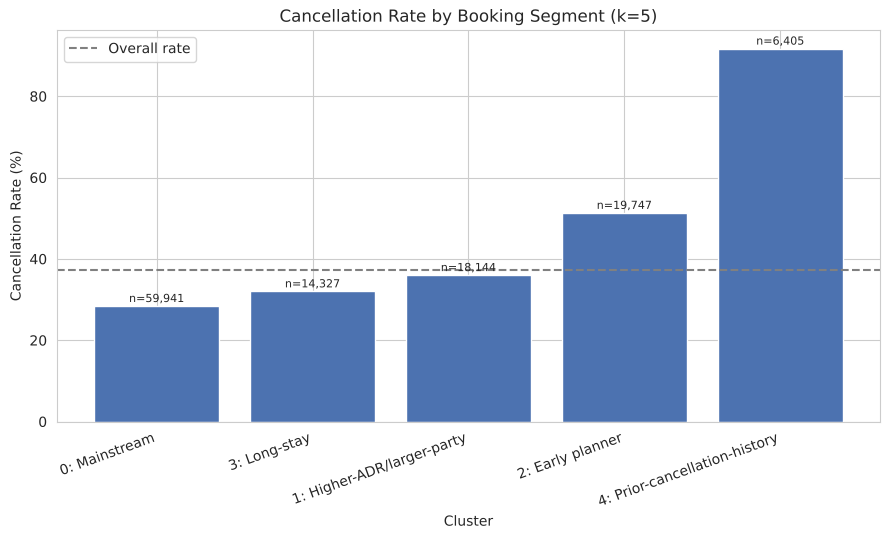

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
order = profile.sort_values("cancellation_rate_pct").index
labels = [f"{c}: {cluster_names_short[c]}" for c in order]
bars = ax.bar(labels, profile.loc[order, "cancellation_rate_pct"], color="#4C72B0")
for bar, (c, n) in zip(bars, profile.loc[order, "n"].items()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"n={n:,}", ha="center", fontsize=8)
ax.axhline(df["is_canceled"].mean() * 100, color="gray", linestyle="--", label="Overall rate")
ax.set_xlabel("Cluster")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_title("Cancellation Rate by Booking Segment (k=5)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "08_cluster_cancellation_rate.png")
plt.show()

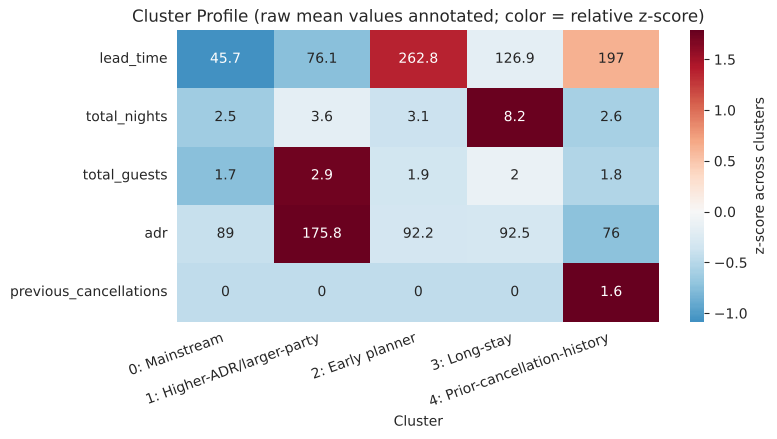

In [11]:
# Normalized profile heatmap (z-scores) so the 5 segments can be compared on one chart
display_feats = ["lead_time_mean", "total_nights_mean", "total_guests_mean", "adr_mean", "previous_cancellations_mean"]
z = (profile[display_feats] - profile[display_feats].mean()) / profile[display_feats].std()
z.columns = [c.replace("_mean", "") for c in z.columns]
col_labels = [f"{c}: {cluster_names_short[c]}" for c in z.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(z.T, annot=profile[display_feats].T.round(1).values, fmt="g", cmap="RdBu_r", center=0,
            xticklabels=col_labels, cbar_kws={"label": "z-score across clusters"}, ax=ax)
ax.set_xlabel("Cluster")
ax.set_title("Cluster Profile (raw mean values annotated; color = relative z-score)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.savefig(fig_dir / "09_cluster_profile_heatmap.png")
plt.show()

## 6. Robustness check: are segments specific to one hotel type?

The proposal's risk-management plan commits to reporting results
separately for the two hotels (one resort, one city) rather than treating
the dataset as representative of hotels generally. This checks whether the
five booking segments are genuinely cross-cutting patterns, or whether a
segment is really just "City Hotel" or "Resort Hotel" relabelled.

In [12]:
hotel_mix = pd.crosstab(df["cluster"], df["hotel"], normalize="index").round(3) * 100
hotel_mix["n"] = df.groupby("cluster")["row_id"].count()
hotel_mix.insert(0, "segment_name", hotel_mix.index.map(cluster_names))
print("Hotel-type composition within each cluster (%):")
print(hotel_mix)
print("\nFor reference, overall dataset mix: City Hotel",
      round((df['hotel'] == 'City Hotel').mean() * 100, 1),
      "% / Resort Hotel", round((df['hotel'] == 'Resort Hotel').mean() * 100, 1), "%")

hotel_mix.to_csv(tab_dir / "10_cluster_hotel_mix.csv")

Hotel-type composition within each cluster (%):
hotel                                         segment_name  ...      n
cluster                                                     ...       
0                 Mainstream (short lead time, short stay)  ...  59941
1        Higher-ADR / larger-party bookings (higher ADR...  ...  18144
2                      Early planner (very long lead time)  ...  19747
3                       Long-stay (longest average nights)  ...  14327
4        Prior-cancellation-history bookings (prior can...  ...   6405

[5 rows x 4 columns]

For reference, overall dataset mix: City Hotel 66.5 % / Resort Hotel 33.5 %


**Finding**: no cluster is purely one hotel type, so the five segments are
not simply a relabelling of `hotel` - but the mix is not uniform either.
Against the dataset's overall 66.5% City / 33.5% Resort split, the
"long-stay" cluster is clearly Resort-skewed (67.3% Resort - roughly
double its overall share, consistent with longer resort-vacation stays),
while "early planner" and "prior-cancellation-history" skew more City than
average (78.0% and 83.7% City respectively). This means part of what
looks like a "segment effect" on cancellation rate in Section 5 is
intertwined with the hotel-type effect from Section 1 of the EDA notebook,
and the cancellation-rate comparison should not be read as independent of
hotel type - consistent with the proposal's caution against generalising
pooled findings across the two different properties.

Cancellation rate (%) by cluster, split by hotel:
hotel    City Hotel  Resort Hotel
cluster                          
0             31.90         20.14
1             36.54         35.00
2             55.54         36.34
3             41.62         27.40
4             93.19         84.24

(n per cell)
hotel    City Hotel  Resort Hotel
cluster                          
0             42351         17590
1             11102          7042
2             15408          4339
3              4680          9647
4              5358          1047

Saved long-format table (cluster, segment_name, hotel, n, n_canceled, cancellation_rate_pct):
 cluster                                                        segment_name        hotel     n  n_canceled  cancellation_rate_pct
       0                            Mainstream (short lead time, short stay)   City Hotel 42351       13511                  31.90
       0                            Mainstream (short lead time, short stay) Resort Hotel 17590        

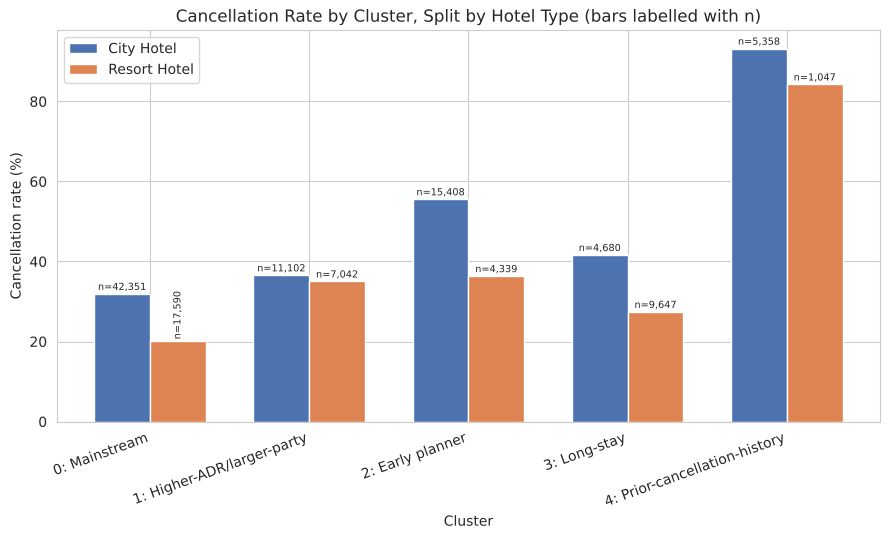

In [13]:
# Does the pooled cancellation-rate ranking across segments hold within each hotel type?
cluster_hotel_rate = (df.groupby(["cluster", "hotel"])["is_canceled"].mean() * 100).unstack().round(2)
cluster_hotel_n = df.groupby(["cluster", "hotel"])["is_canceled"].count().unstack()
print("Cancellation rate (%) by cluster, split by hotel:")
print(cluster_hotel_rate)
print("\n(n per cell)")
print(cluster_hotel_n)

# Export as a long table with both n and n_canceled, so the denominator travels
# with the rate even if someone only pulls the CSV (not the notebook output above).
cluster_hotel_long = df.groupby(["cluster", "hotel"])["is_canceled"].agg(n="count", n_canceled="sum").reset_index()
cluster_hotel_long["cancellation_rate_pct"] = (cluster_hotel_long["n_canceled"] / cluster_hotel_long["n"] * 100).round(2)
cluster_hotel_long.insert(1, "segment_name", cluster_hotel_long["cluster"].map(cluster_names))
cluster_hotel_long.to_csv(tab_dir / "11_cluster_hotel_cancellation_rate.csv", index=False)
print("\nSaved long-format table (cluster, segment_name, hotel, n, n_canceled, cancellation_rate_pct):")
print(cluster_hotel_long.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(cluster_hotel_rate))
width = 0.35
chart_labels = [f"{c}: {cluster_names_short[c]}" for c in cluster_hotel_rate.index]
bars_city = ax.bar(x - width/2, cluster_hotel_rate["City Hotel"], width, label="City Hotel", color="#4C72B0")
bars_resort = ax.bar(x + width/2, cluster_hotel_rate["Resort Hotel"], width, label="Resort Hotel", color="#DD8452")
for bars, col in [(bars_city, "City Hotel"), (bars_resort, "Resort Hotel")]:
    for bar, c in zip(bars, cluster_hotel_rate.index):
        n = cluster_hotel_n.loc[c, col]
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"n={n:,}",
                ha="center", fontsize=7, rotation=90 if bar.get_height() < 25 else 0)
ax.set_xticks(x); ax.set_xticklabels(chart_labels, rotation=20, ha="right")
ax.set_xlabel("Cluster"); ax.set_ylabel("Cancellation rate (%)")
ax.set_title("Cancellation Rate by Cluster, Split by Hotel Type (bars labelled with n)")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "11_cluster_cancellation_by_hotel.png")
plt.show()

**Finding**: the pooled ranking in Section 5 does not always hold within a
single hotel type. Pooled across both hotels, "higher-ADR/larger-party" (cluster 1,
36.0% cancellation) ranks *above* "long stay" (cluster 3, 32.0%). But
within City Hotel alone, that ranking reverses: "long stay" is 41.6%
against "higher-ADR/larger-party"'s 36.5% - the opposite order. Within
Resort Hotel, "long stay" is 27.4% against "higher-ADR/larger-party"'s
35.0% - the same direction as the pooled ranking, with a 7.6-point gap
that is, if anything, larger than the City reversal above; the point is
not that Resort is "close" but that only City actually flips the order.
This is a direct consequence of the hotel-mix
imbalance found above ("long stay" is Resort-skewed overall, but its
City-Hotel subset cancels much more than its Resort-Hotel subset) and is
the clearest evidence in this analysis that a single pooled
cancellation-rate ranking across segments should not be quoted without
the hotel-type qualifier - any report or PPT claim such as "long-stay
bookings cancel less than higher-ADR/larger-party bookings" needs to specify which
hotel, or it can be read backwards for City Hotel specifically.

In [14]:
# Duplicate-row rate on this notebook's actual data basis (cleaned dataset, excluding row_id)
dup_mask = df.drop(columns=["row_id"]).duplicated()
print(f"Duplicate rows: {dup_mask.sum():,} / {len(df):,} = {dup_mask.mean()*100:.2f}%")

Duplicate rows: 33,985 / 118,564 = 28.66%


## Summary and limitations

- K-means on five standardized, outlier-treated numeric features (fit on
  the training set, applied to the full cleaned dataset) separates bookings
  into 5 segments with distinct average lead time, stay length, party size,
  ADR, and prior-cancellation history.
- Cancellation rate varies sharply by segment, from the lowest (mainstream,
  short-lead bookings) to the highest (bookings with prior cancellation
  history, ~92% - far above the 37.3% overall rate). This comparison is
  descriptive only: clustering used no cancellation information, so this is
  not evidence of a causal relationship between segment membership and
  cancellation.
- Limitation: per-cluster silhouette analysis shows the "higher-ADR/larger-party" and
  "long stay" segments are less internally cohesive than the other three
  (lower average silhouette, more boundary-ambiguous points) - their
  profiles should be read as the dominant pattern within a somewhat fuzzier
  group, not a sharply separated population.
- Limitation: outlier capping and the log transform were derived from the
  training set only; the duplicate-row rate computed above (28.66% on this
  clustering notebook's own data basis) was not specifically corrected for
  in this clustering step (duplicate handling is being investigated
  separately on the classification side). Note this is a different figure
  from the ~26.8% cited in A's initial data inspection - that number was
  computed on the raw, uncleaned 119,390-row dataset (which still included
  columns later dropped before cleaning); 28.66% is the rate on the
  cleaned dataset these two notebooks actually use.
- Limitation: segment composition is not independent of hotel type (e.g.
  "long-stay" skews Resort, "prior-cancellation-history" skews City), and this is
  not a minor caveat: the pooled cancellation-rate ranking of "higher-ADR/larger-party"
  (36.0%) above "long stay" (32.0%) in Section 5 reverses within City
  Hotel alone (41.6% vs. 36.5% - see Section 6). Per the proposal's
  risk-management plan, segment cancellation-rate comparisons should be
  reported with the hotel type specified, not as a single pooled ranking.
